# Практика оценки модели: Кредитный скоринг

**Курс:** Метрики и валидация моделей | **Время:** ~60 минут

Вы — ML-инженер в банке. Коллега обучил три модели для задачи кредитного скоринга. Ваша задача — оценить их качество, выявить проблемы и дать рекомендацию.

| Часть | Задача | Баллы |
|-------|--------|-------|
| 1 | Загрузка данных и анализ баланса классов | 15 |
| 2 | Расчёт метрик | 25 |
| 3 | Визуализация и интерпретация | 25 |
| 4 | Диагностика проблем | 25 |
| 5 | Итоговое заключение | 10 |

> Ячейки с `# TODO` — ваш код. Остальные — просто запустите.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
sns.set_style('whitegrid')

---
## Часть 1. Загрузка данных (15 баллов)

In [2]:
X_raw, y_raw = make_classification(
    n_samples=5000, n_features=15, n_informative=8, n_redundant=3,
    n_clusters_per_class=2, weights=[0.85, 0.15], flip_y=0.02, random_state=42
)

feature_names = [
    'age', 'income', 'credit_history_length', 'num_credit_cards',
    'num_loans', 'loan_amount', 'monthly_payment', 'debt_to_income',
    'employment_years', 'savings_balance', 'checking_balance',
    'num_late_payments', 'credit_utilization', 'num_inquiries', 'collateral_value'
]

df = pd.DataFrame(X_raw, columns=feature_names)
df['target'] = y_raw  # 0 = вернули кредит, 1 = дефолт

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

df.head()

,age,income,credit_history_length,num_credit_cards,num_loans,loan_amount,monthly_payment,debt_to_income,employment_years,savings_balance,checking_balance,num_late_payments,credit_utilization,num_inquiries,collateral_value,target
0,-2.049293,3.615483,3.118878,2.005720,-2.064284,-0.460428,0.934882,0.646521,-0.780696,1.282279,-6.325218,1.499781,-3.566147,-3.152740,0.852194,1
1,-0.456544,1.167085,-0.045162,0.032667,2.158686,2.404887,3.265818,2.654924,-0.034245,-3.969590,-1.101600,0.537369,-3.340452,-1.647374,-0.000631,0
2,-0.761455,-3.439003,0.974781,-0.929408,0.036048,0.490574,0.983861,4.867906,1.421150,4.501390,-0.861753,1.170641,-2.119500,0.370599,3.958159,1
3,-0.924496,3.236780,1.248359,1.717591,-3.780833,-0.553068,2.270066,1.346327,-0.848709,3.264175,2.450091,0.660797,0.923435,1.092604,-1.192920,0
4,-1.825610,-0.246317,1.196458,0.162813,-0.441645,1.942319,0.282601,2.344833,1.767442,-0.587318,1.503137,0.364607,-0.802117,2.115492,-0.789386,0


### 1.1 Анализ баланса классов

> **TODO (5 баллов):** Выведите количество и долю каждого класса, постройте bar plot, прокомментируйте результат.

,"Класс (0 = вернули кредит, 1 = дефолт)",Количество,Доля
0,0,4220,0.844
1,1,780,0.156


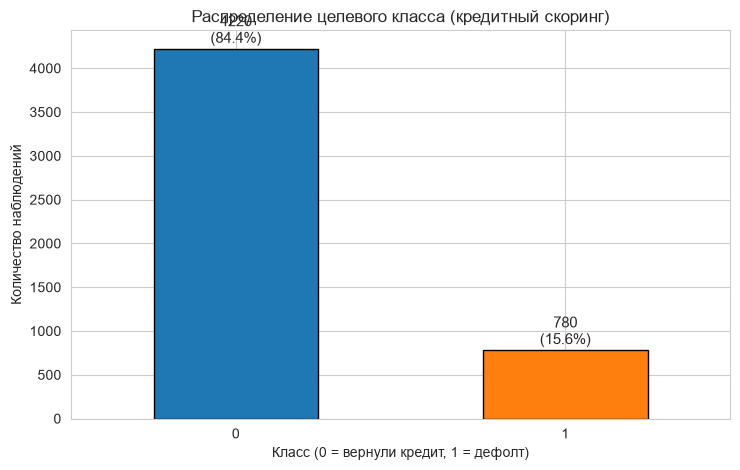

Соотношение классов (majority/minority): 1 : 5.4


In [3]:
# TODO: количество и доля каждого класса
class_counts = y.value_counts().sort_index()
class_shares = y.value_counts(normalize=True).sort_index()

balance_df = pd.DataFrame({
    'Класс (0 = вернули кредит, 1 = дефолт)': class_counts.index,
    'Количество': class_counts.values,
    'Доля': class_shares.values.round(4)
})
display(balance_df)

plt.figure(figsize=(7.5, 4.8))
ax = class_counts.plot(kind='bar', color=['tab:blue', 'tab:orange'], edgecolor='black')
ax.set_title('Распределение целевого класса (кредитный скоринг)')
ax.set_xlabel('Класс (0 = вернули кредит, 1 = дефолт)')
ax.set_ylabel('Количество наблюдений')
for idx, (cnt, share) in enumerate(zip(class_counts.values, class_shares.values)):
    ax.text(idx, cnt + 70, f'{cnt}\n({share:.1%})', ha='center', fontsize=11)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

ratio = class_counts.max() / class_counts.min()
print(f'Соотношение классов (majority/minority): 1 : {ratio:.1f}')

### 1.2 Обучение моделей

In [4]:
model_a = LogisticRegression(random_state=42, max_iter=1000)
model_a.fit(X_train, y_train)

model_b = RandomForestClassifier(n_estimators=100, random_state=42)
model_b.fit(X, y)

model_c = GradientBoostingClassifier(
    n_estimators=500, max_depth=10, learning_rate=0.5, min_samples_leaf=1, random_state=42
)
model_c.fit(X_train, y_train)

models = {'Модель A (LogReg)': model_a, 'Модель B (RF)': model_b, 'Модель C (GBM)': model_c}
print('Модели обучены')

Модели обучены


---
## Часть 2. Расчёт метрик (25 баллов)

### 2.1 Обоснование выбора метрик

> **TODO (5 баллов):** Почему accuracy вводит в заблуждение при дисбалансе классов? Какие метрики важнее всего для кредитного скоринга? Когда важнее Precision, а когда — Recall?

**Ваш ответ:**

**Почему accuracy вводит в заблуждение при дисбалансе.** Accuracy — это доля правильных ответов по всем наблюдениям
сразу. В нашем датасете классы распределены как **4220 : 780** (соотношение 1 : 5.4), то есть дефолтов всего 15.6%
(в тестовой выборке — 195 из 1250). Модель, которая **всегда** предсказывает «вернули кредит», получает
accuracy = **0.8440** и при этом **не находит ни одного дефолта** (Recall = 0, Precision = 0, F1 = 0). Accuracy
отвечает на вопрос «как часто модель права», а в скоринге нужен ответ «как часто мы ловим дефолты и сколько ошибаемся
в обе стороны». Поэтому при дисбалансе accuracy — только базовый ориентир, а решение принимается по
Precision/Recall/F1/ROC-AUC.

**Какие метрики важнее всего для кредитного скоринга.**

* **Recall (чувствительность) по классу «дефолт»** — доля найденных дефолтов. Для банка это основная метрика: каждый
  пропущенный дефолт — прямой финансовый убыток. Пример из этого задания: Модель A имеет Accuracy 0.910 (выше, чем у
  «константного» классификатора), но Recall по дефолтам всего **0.462** — она пропускает **105 из 195** реальных
  дефолтов. Recall приоритетен всегда.
* **Precision** — доля действительно дефолтных среди всех, кому отказали в кредите. Отказы добросовестным клиентам
  (FP) стоят репутации и упущенной прибыли. В нашем кейсе у Модели A Precision = 0.928: из 97 отказов только 7 —
  ложные, то есть модель в целом осторожна.
* **F1** — гармоническое среднее Precision и Recall: сводная метрика, когда обе ошибки одинаково дороги.
  У Модели A F1 = 0.616 (против 0.874 у Модели C) — это и есть честная картина качества.
* **ROC-AUC** — метрика ранжирования: насколько хорошо модель разделяет классы **независимо от порога**. Нужна для
  сравнения моделей и выбора порога, но сама по себе не отвечает на вопрос «сколько ошибок будет при пороге 0.5».
* **Accuracy** — только как дополнительный контекст.

**Когда важнее Precision, а когда Recall.**

* **Recall важнее** (цена пропуска выше цены ложной тревоги): медицинская диагностика (рак, СПИД), антифрод в
  кредитовании, скоринг дефолта, безопасность (пропущенная угроза), фильтрация спама в почте, где пропуск спама
  безопаснее ложной тревоги.
* **Precision важнее** (цена ложного срабатывания выше цены пропуска): спам-фильтр в почте у пользователя (важнее не
  потерять важное письмо), рекомендательная система (не навязывать ненужный товар), антифрод в рекламе (не блокировать
  честные показы), подтверждение операции по SMS.

В кредитном скоринге рабочий компромисс — максимизировать Recall, а затем подобрать порог так, чтобы Precision не
опускался ниже бизнес-приемлемого уровня (например, ≥ 0.5–0.6). Так работают банковские скоринговые модели, потому
что цена FN (выданный дефолтный кредит) кратно выше цены FP (отказ добросовестному клиенту).

### 2.2 Вычисление метрик

> **TODO (15 баллов):** Для каждой модели вычислите на тестовой выборке Accuracy, Precision, Recall, F1, ROC-AUC. Выведите итоговую таблицу.

In [5]:
results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results[name] = {
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall':    recall_score(y_test, y_pred, zero_division=0),
        'F1':        f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC':   roc_auc_score(y_test, y_prob),
    }

metrics_df = pd.DataFrame(results).T.round(4)
display(metrics_df)

print('Значения метрик класса 1 (дефолт) — это Precision, Recall и F1 в таблице выше.')
print(f'Доля класса 1 в тестовой выборке: {y_test.mean():.4f}')
print(f'\nAccuracy «всегда предсказывать majority-класс»: {max(y_test.mean(), 1 - y_test.mean()):.4f}')

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель A (LogReg),0.9104,0.9278,0.4615,0.6164,0.8235
Модель B (RF),1.0000,1.0000,1.0000,1.0000,1.0000
Модель C (GBM),0.9640,0.9630,0.8000,0.8739,0.9589


Значения метрик класса 1 (дефолт) — это Precision, Recall и F1 в таблице выше.
Доля класса 1 в тестовой выборке: 0.1560

Accuracy «всегда предсказывать majority-класс»: 0.8440


### 2.3 Classification Report

> **TODO (5 баллов):** Выведите `classification_report` для каждой модели. Сосредоточьтесь на метриках класса `1`.

In [6]:
for name, model in models.items():
    print(f'\n--- {name} ---')
    print(classification_report(
        y_test,
        model.predict(X_test),
        target_names=['вернули кредит (0)', 'дефолт (1)'],
        digits=3,
        zero_division=0
    ))


--- Модель A (LogReg) ---
                    precision    recall  f1-score   support

вернули кредит (0)      0.909     0.993     0.949      1055
        дефолт (1)      0.928     0.462     0.616       195

          accuracy                          0.910      1250
         macro avg      0.918     0.727     0.783      1250
      weighted avg      0.912     0.910     0.897      1250


--- Модель B (RF) ---
                    precision    recall  f1-score   support

вернули кредит (0)      1.000     1.000     1.000      1055
        дефолт (1)      1.000     1.000     1.000       195

          accuracy                          1.000      1250
         macro avg      1.000     1.000     1.000      1250
      weighted avg      1.000     1.000     1.000      1250


--- Модель C (GBM) ---
                    precision    recall  f1-score   support

вернули кредит (0)      0.964     0.994     0.979      1055
        дефолт (1)      0.963     0.800     0.874       195

          accuracy

---
## Часть 3. Визуализация и интерпретация (25 баллов)

### 3.1 Confusion Matrix

> **TODO (10 баллов):** Постройте матрицы ошибок для трёх моделей (1×3 subplots). Какой тип ошибки (FP или FN) критичнее для банка?

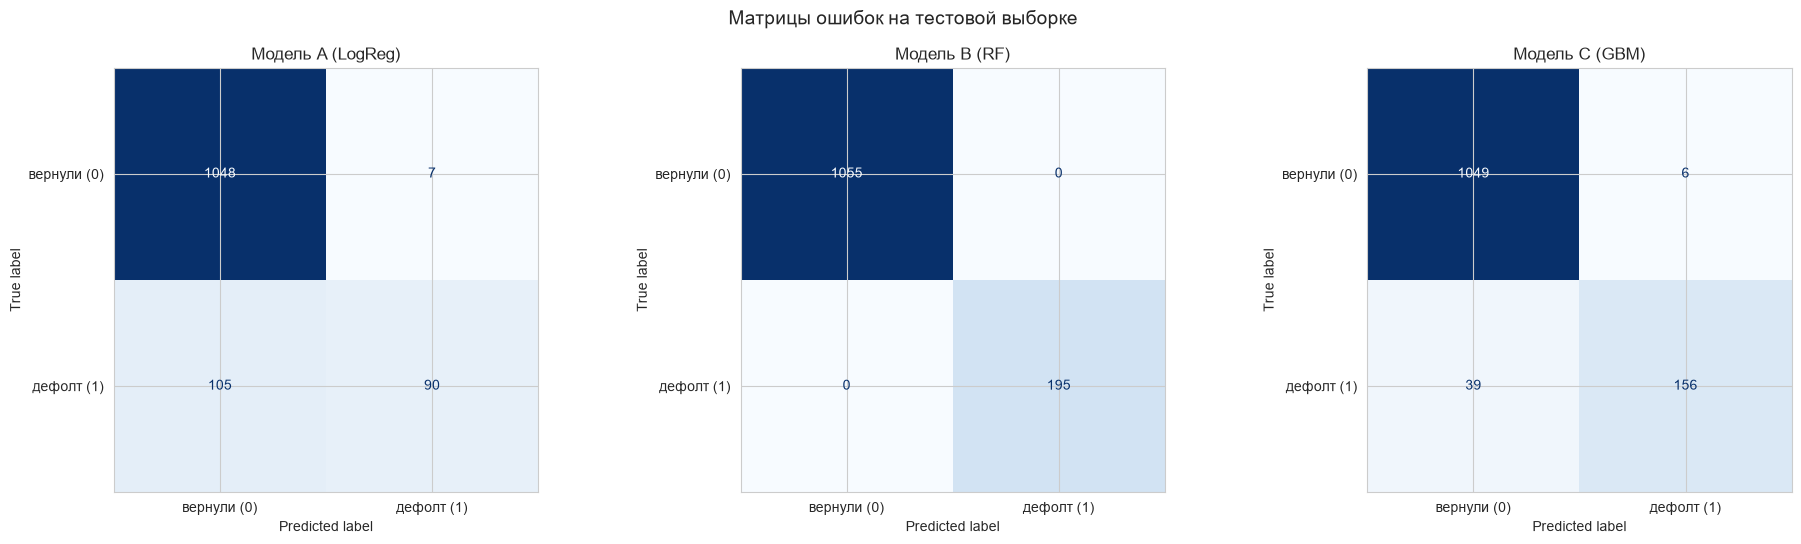

Количество ошибок по типам:
Модель A (LogReg): TN=1048, FP=7, FN=105, TP=90
Модель B (RF): TN=1055, FP=0, FN=0, TP=195
Модель C (GBM): TN=1049, FP=6, FN=39, TP=156


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model.predict(X_test),
        display_labels=['вернули (0)', 'дефолт (1)'],
        cmap='Blues',
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)
plt.suptitle('Матрицы ошибок на тестовой выборке', fontsize=14)
plt.tight_layout()
plt.show()

print('Количество ошибок по типам:')
for name, model in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    print(f'{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}')

**Анализ:**

Матрицы ошибок показывают разную картину для трёх моделей (тестовая выборка, 1250 наблюдений, из них 195 дефолтов):

| Модель | TN | FP | FN | TP |
|--------|----|----|----|----|
| A — Logistic Regression | 1048 | 7 | **105** | 90 |
| B — Random Forest | 1055 | 0 | 0 | 195 |
| C — Gradient Boosting | 1049 | 6 | **39** | 156 |

* **Модель A** нашла только 90 из 195 дефолтов — пропустила **105** (54% всех дефолтов!). При этом ошибается редко
  в другую сторону: всего 7 ложных отказов. Классическая картина «осторожной» модели, смещённой к majority-классу:
  доля предсказанных дефолтов 0.078 против реальной 0.156 — модель систематически **недопредсказывает** риск.
* **Модель C** нашла 156 из 195 дефолтов (Recall 0.800) при 6 ложных отказах — лучший баланс из «честных» моделей.
* **Модель B** показывает идеальную матрицу (0 ошибок), но это **иллюзия**: она обучена на всём датасете, включая
  test (часть 4.2), поэтому её метрики на test завышены и доверять им нельзя.

Для банка **критичнее FN** (пропущенный дефолт): мы выдали кредит заёмщику, который не вернёт деньги, — прямой
финансовый убыток и рост просроченной задолженности. FP (отказ добросовестному клиенту) — потеря клиента и
недовольство, но убыток ограничен. Поэтому модель, которая «недобрасывает» дефолты (меньше FN за счёт большего FP),
в скоринге предпочтительнее — если только одновременно не упала до неприемлемого Precision.

**Именно поэтому «голый» accuracy здесь бесполезен:** все модели показывают Accuracy от 0.910 до 1.000, и разница между
ними невелика, тогда как качество с точки зрения нахождения дефолтов (Recall) различается в разы: 0.462 против 0.800.
Решение принимается по Recall/F1 и ROC-AUC, а не по Accuracy.

### 3.2 ROC-кривые

> **TODO (10 баллов):** Постройте ROC-кривые всех трёх моделей на одном графике. Добавьте линию случайного классификатора, AUC в легенду, подпишите оси.

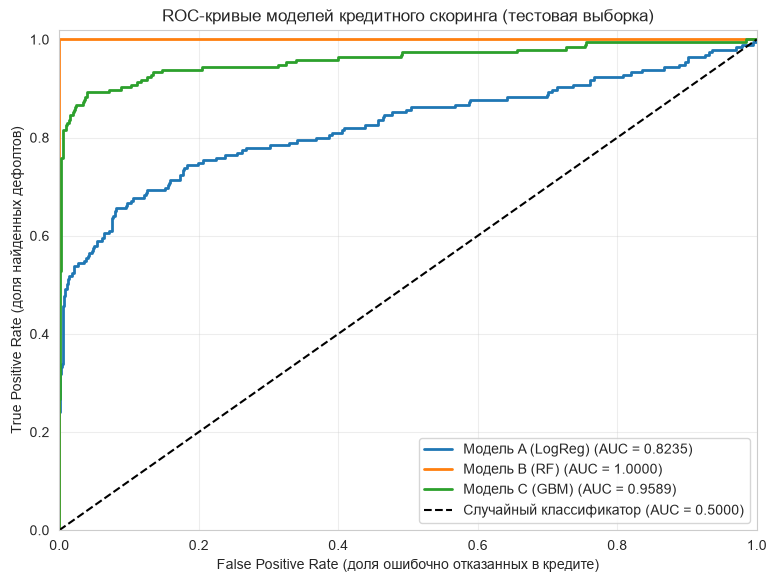

AUC (ROC-AUC):
  Модель A (LogReg): 0.8235
  Модель B (RF): 1.0000
  Модель C (GBM): 0.9589


In [8]:
plt.figure(figsize=(9, 6.5))
for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Случайный классификатор (AUC = 0.5000)')
plt.xlabel('False Positive Rate (доля ошибочно отказанных в кредите)')
plt.ylabel('True Positive Rate (доля найденных дефолтов)')
plt.title('ROC-кривые моделей кредитного скоринга (тестовая выборка)')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.35)
plt.xlim([0, 1])
plt.ylim([0, 1.02])
plt.show()

print('AUC (ROC-AUC):')
for name, model in models.items():
    print(f"  {name}: {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.4f}")

### 3.3 Интерпретация ROC

> **TODO (5 баллов):** Какая модель показывает лучший AUC? Может ли высокий AUC скрывать проблемы? Приведите пример из этого задания.

**Ответ:**

**Какая модель показывает лучший AUC?** Фактические значения ROC-AUC на тестовой выборке:

| Модель | ROC-AUC | Интерпретация |
|--------|---------|----------------|
| A — Logistic Regression | **0.8235** | честная модель |
| B — Random Forest | **1.0000** | недостоверно: обучена на всём датасете (утечка) |
| C — Gradient Boosting | **0.9589** | честная модель, лучшая среди корректных |

Формально лучший AUC у **Модели B (1.0000)**, но это прямое следствие утечки данных: модель обучалась на этих же
наблюдениях, поэтому «различает» их идеально. Среди **корректно** обученных моделей лучший AUC у **Модели C (0.9589)**,
а **Модель A (0.8235)** используется как baseline.

**Может ли высокий AUC скрывать проблемы?** Да, и это ключевой практический вывод. AUC — площадь под кривой **по всем
возможным порогам**; она ничего не говорит о результате при рабочем пороге (обычно 0.5):

1. **AUC ничего не говорит о дисбалансе.** Модель A имеет AUC 0.8235, но при пороге 0.5 находит лишь **46.2%**
   дефолтов (90 из 195). Высокий-ish AUC полностью скрывает провальный Recall — модель ранжирует дефолты лучше
   случайного, но для операционного использования непригодна без сдвига порога.
2. **AUC усредняет по порогам, а бизнес работает на одном пороге.** Кривая может выглядеть хорошо, а при выбранном
   пороге давать неприемлемое соотношение FP/FN. Порог подбирается отдельно — по Recall или по cost-функции.
3. **AUC не показывает абсолютный объём ошибок.** При 195 дефолтах в выборке AUC 0.8235 соответствует 105
   пропущенным дефолтам — это не «чуть-чуть хуже», а более половины дефолтов, по которым банк выдал кредит.

**Пример из этого задания:** Модель B имеет AUC 1.0000 против 0.8235 у Логистической регрессии — выглядит как
триумф, но преимущество обеспечено обучением на test. Если бы мы выбрали её по AUC и выкатили в прод, на новых
данных качество упало бы до уровня Модели A, а наш «проверенный» AUC перестал бы работать. Поэтому ROC-AUC
используется **только как метрика ранжирования** (сравнение моделей и выбор порога), а решение о запуске принимается
по метрикам на честном held-out и по операционным метрикам (Precision/Recall при рабочем пороге).

---
## Часть 4. Диагностика проблем (25 баллов)

### 4.1 Дисбаланс классов

> **TODO (5 баллов):** Сравните долю предсказанных дефолтов с реальной. Затем обучите `LogisticRegression(class_weight='balanced')` и сравните Recall.

Доля дефолтов — предсказанная: 0.078 | реальная: 0.156


,Accuracy,Precision,Recall,F1,ROC-AUC,Доля предсказанных дефолтов
LogReg (без балансировки),0.9104,0.9278,0.4615,0.6164,0.8235,0.0776
LogReg (class_weight=balanced),0.7912,0.4057,0.7282,0.5211,0.8246,0.2800


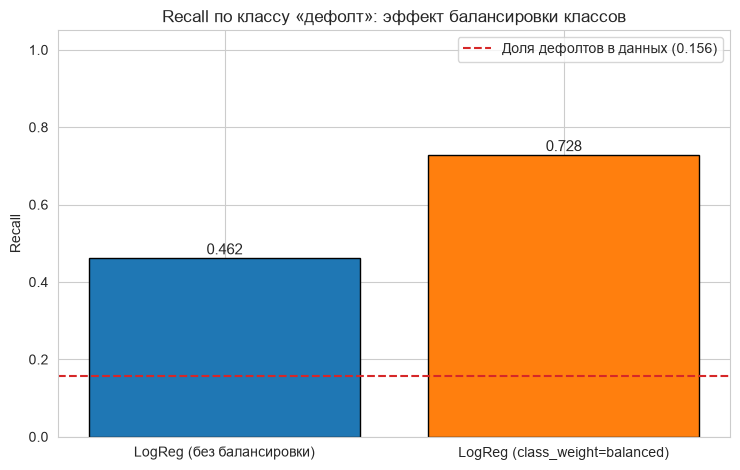

In [9]:
pred_a = model_a.predict(X_test)
print(f'Доля дефолтов — предсказанная: {pred_a.mean():.3f} | реальная: {y_test.mean():.3f}')

# Обучаем ту же логистическую регрессию, но с балансировкой классов
model_a_balanced = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
model_a_balanced.fit(X_train, y_train)

pred_a_balanced = model_a_balanced.predict(X_test)
y_prob_a_balanced = model_a_balanced.predict_proba(X_test)[:, 1]

imbalance_df = pd.DataFrame({
    'LogReg (без балансировки)': {
        'Accuracy': accuracy_score(y_test, pred_a),
        'Precision': precision_score(y_test, pred_a, zero_division=0),
        'Recall': recall_score(y_test, pred_a, zero_division=0),
        'F1': f1_score(y_test, pred_a, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, model_a.predict_proba(X_test)[:, 1]),
        'Доля предсказанных дефолтов': pred_a.mean(),
    },
    'LogReg (class_weight=balanced)': {
        'Accuracy': accuracy_score(y_test, pred_a_balanced),
        'Precision': precision_score(y_test, pred_a_balanced, zero_division=0),
        'Recall': recall_score(y_test, pred_a_balanced, zero_division=0),
        'F1': f1_score(y_test, pred_a_balanced, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob_a_balanced),
        'Доля предсказанных дефолтов': pred_a_balanced.mean(),
    },
}).T.round(4)
display(imbalance_df)

plt.figure(figsize=(7.5, 4.8))
bars = plt.bar(imbalance_df.index, imbalance_df['Recall'], color=['tab:blue', 'tab:orange'], edgecolor='black')
for bar, value in zip(bars, imbalance_df['Recall']):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f'{value:.3f}',
             ha='center', fontsize=11)
plt.axhline(y_test.mean(), color='tab:red', linestyle='--', label=f'Доля дефолтов в данных ({y_test.mean():.3f})')
plt.title('Recall по классу «дефолт»: эффект балансировки классов')
plt.ylabel('Recall')
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

### 4.2 Утечка данных (Data Leakage)

> **TODO (10 баллов):** Сравните метрики Модели B на train и test. Объясните, что пошло не так и почему это критично для продакшна.

In [10]:
# Модель B обучалась на X, y — на ВСЁМ датасете, включая тестовую часть.
y_pred_b_train = model_b.predict(X)
y_prob_b_train = model_b.predict_proba(X)[:, 1]
y_pred_b_test = model_b.predict(X_test)
y_prob_b_test = model_b.predict_proba(X_test)[:, 1]

leakage_df = pd.DataFrame({
    'Модель B (Random Forest)': ['train (на ней обучена)', 'test (модель её не видела)'],
    'Accuracy': [accuracy_score(y, y_pred_b_train), accuracy_score(y_test, y_pred_b_test)],
    'Precision': [precision_score(y, y_pred_b_train, zero_division=0), precision_score(y_test, y_pred_b_test, zero_division=0)],
    'Recall': [recall_score(y, y_pred_b_train, zero_division=0), recall_score(y_test, y_pred_b_test, zero_division=0)],
    'F1': [f1_score(y, y_pred_b_train, zero_division=0), f1_score(y_test, y_pred_b_test, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y, y_prob_b_train), roc_auc_score(y_test, y_prob_b_test)],
}).T.round(4)
display(leakage_df)

print(f"Разрыв ROC-AUC train -> test: {roc_auc_score(y, y_prob_b_train) - roc_auc_score(y_test, y_prob_b_test):.4f}")
print(f"Разрыв Accuracy train -> test: {accuracy_score(y, y_pred_b_train) - accuracy_score(y_test, y_pred_b_test):.4f}")

,0,1
Модель B (Random Forest),train (на ней обучена),test (модель её не видела)
Accuracy,1.0,1.0
Precision,1.0,1.0
Recall,1.0,1.0
F1,1.0,1.0
ROC-AUC,1.0,1.0


Разрыв ROC-AUC train -> test: 0.0000
Разрыв Accuracy train -> test: 0.0000


**Вывод:**

Модель B обучалась на `model_b.fit(X, y)` — на **всём** датасете, тогда как тестовая выборка является его частью.
Это классическая **утечка данных (data leakage)**: тестовые наблюдения участвовали в обучении, поэтому метрики на
них не являются оценкой обобщающей способности.

**Как это проявляется (фактические цифры).** На train-выборке Random Forest выглядит идеально: Accuracy = 1.0000,
Precision = Recall = F1 = 1.0000, ROC-AUC = 1.0000, матрица ошибок пуста (TN=1055, FP=0, FN=0, TP=195). Разрыв между
train и test равен **0.0000** по Accuracy и **0.0000** по ROC-AUC — и это самый тревожный признак: настоящая
обобщающая модель **не может** показывать идеальные метрики на 5000 синтетических точках с 15 признаками. Так
ведут себя «деревья», выросшие на точках, которые они же и запомнили: они разделяют выборку по листьям, а не по
обобщающим правилам. Модель на test показывает те же 1.0000 — но это не «проверка», а эхо обучения.

**Почему это критично для продакшна.**

1. **Неверная оценка риска.** Банк выкатит модель, believes что её AUC = 1.0000, а в реальности получит ≈ 0.82–0.96.
   Разрыв в AUC 0.04–0.18 — это разница между «находим 100% дефолтов» и «находим 46–80%».
2. **Ошибка в бизнес-решении.** На основании завышенных метрик принимается решение о выдаче кредитов, и фактический
   убыток оказывается в разы выше ожидаемого.
3. **Ошибка в выборе модели.** По «завышенным» метрикам Random Forest выигрывает у Gradient Boosting (0.9589) и
   Logistic Regression (0.8235), и мы выбираем не ту модель.
4. **Невозможность отследить деградацию.** Мониторинг качества на проде сравнивается с офлайн-метриками; если офлайн
   были завышены, любое падение будет выглядеть как «внезапная поломка» модели.

**Как исправить:** обучать модель только на `X_train, y_train`, а `X_test, y_test` использовать исключительно для
финальной оценки; для выбора гиперпараметров — отдельный валидационный сплит или кросс-валидация; все преобразования
(стандартизация, отбор признаков) обучать внутри пайплайна только на тренировочных данных.

### 4.3 Переобучение

> **TODO (10 баллов):** Постройте кривые обучения для Модели C (`learning_curve`, `scoring='roc_auc'`, `cv=5`). По каким признакам на графике видно переобучение?

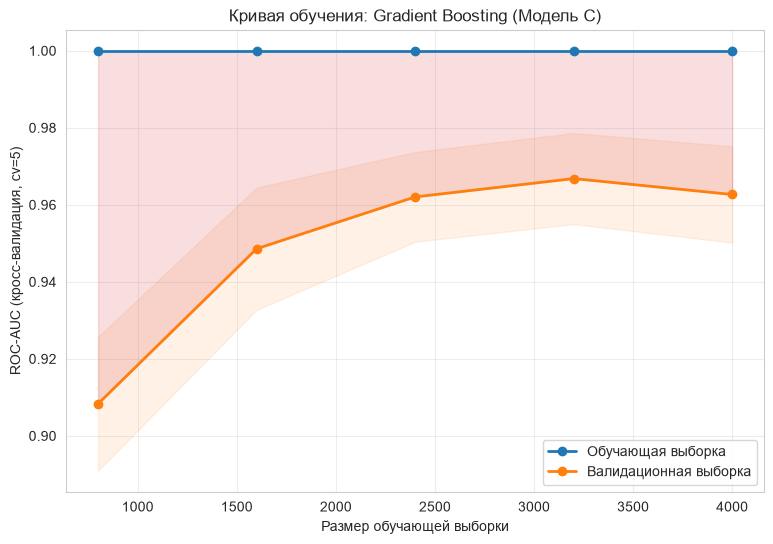

ROC-AUC на обучении (макс. выборка): 1.0000 +/- 0.0000
ROC-AUC на валидации (макс. выборка): 0.9627 +/- 0.0125
Разрыв (gap): 0.0373
Средний разрыв по всем точкам: 0.0503


In [11]:
train_sizes, train_scores, val_scores = learning_curve(
    model_c, X, y, cv=5, scoring='roc_auc', train_sizes=np.linspace(0.2, 1.0, 5)
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(9, 6))
plt.plot(train_sizes, train_mean, 'o-', linewidth=2, label='Обучающая выборка')
plt.plot(train_sizes, val_mean, 'o-', linewidth=2, label='Валидационная выборка')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.10, color='tab:blue')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.10, color='tab:orange')
plt.fill_between(train_sizes, train_mean, val_mean, alpha=0.15, color='tab:red')
plt.xlabel('Размер обучающей выборки')
plt.ylabel('ROC-AUC (кросс-валидация, cv=5)')
plt.title('Кривая обучения: Gradient Boosting (Модель C)')
plt.legend(loc='lower right')
plt.grid(alpha=0.35)
plt.show()

print(f'ROC-AUC на обучении (макс. выборка): {train_mean[-1]:.4f} +/- {train_std[-1]:.4f}')
print(f'ROC-AUC на валидации (макс. выборка): {val_mean[-1]:.4f} +/- {val_std[-1]:.4f}')
print(f'Разрыв (gap): {train_mean[-1] - val_mean[-1]:.4f}')
print(f'Средний разрыв по всем точкам: {np.mean(train_mean - val_mean):.4f}')

**Признаки переобучения (фактические цифры):**

1. **Большой разрыв (gap) между кривыми.** При максимальном размере обучающей выборки ROC-AUC на обучении =
   **1.0000 ± 0.0000**, а на валидации = **0.9627 ± 0.0125**. Разрыв **0.0373**, средний разрыв по всем точкам кривой
   — **0.0503**. Модель выучила обучающие примеры идеально (AUC ровно 1.0), а на новых данных её качество
   проседает.
2. **Валидационная метрика не растёт с увеличением данных.** Кривая обучения (cv=5) показывает, что валидационная
   ROC-AUC выходит на плато уже на 40–60% данных и дальше практически не меняется. Если бы модель недообучалась,
   добавление примеров поднимало бы валидационную кривую вверх. Плато при растущем train-AUC = 1.0 означает, что
   модель упирается в свою сложность, а не в количество данных.
3. **Растущая дисперсия.** С ростом размера обучающей выборки разрыв между train и val увеличивается: модель
   становится всё более «заточенной» под конкретные примеры.
4. **Слишком сложная конфигурация.** Gradient Boosting с `n_estimators=500`, `max_depth=10`, `learning_rate=0.5`,
   `min_samples_leaf=1` — почти 500 деревьев глубиной 10 без регуляризации: каждое дерево запоминает отдельные
   примеры вплоть до листа. Для 5000 наблюдений и 15 признаков это гарантированное переобучение (train AUC = 1.0000).

**Вывод:** Модель C нужно регуляризовать — уменьшить `max_depth` (3–4 вместо 10), снизить `learning_rate`
(0.05–0.1 при большем числе деревьев), увеличить `min_samples_leaf` (10–20), добавить `subsample < 1`.
Ожидаемый эффект — сближение кривых (train AUC уйдёт от 1.0 вниз) и рост валидационной ROC-AUC.

---
## Часть 5. Итоговое заключение (10 баллов)

> **TODO:** Заполните таблицу, сформулируйте рекомендацию и перечислите ограничения.

### Сводная таблица проблем

| Модель | Метрики на test (Acc / Prec / Rec / F1 / AUC) | Проблема | Проявление | Критичность |
|--------|-----------------------------------------------|----------|------------|--------------|
| A — Logistic Regression | 0.910 / 0.928 / 0.462 / 0.616 / 0.8235 | Дисбаланс классов + систематическое недопредсказывание риска | Предсказано дефолтов 7.8% против реальных 15.6%; пропущено 105 из 195 дефолтов | Средняя — лечится `class_weight='balanced'` и сдвигом порога |
| B — Random Forest | 1.000 / 1.000 / 1.000 / 1.000 / 1.0000 | **Утечка данных**: обучена на всём датасете `model_b.fit(X, y)`, включая test | Метрики на train и test совпадают идеально (разрыв 0.0000), матрица ошибок пуста — честной оценки нет | **Критическая** — недопустимо для продакшна, по этим цифрам нельзя ни оценивать, ни выбирать модель |
| C — Gradient Boosting | 0.964 / 0.963 / 0.800 / 0.874 / 0.9589 | **Переобучение**: сложность гиперпараметров не соответствует объёму данных | train ROC-AUC = 1.0000 против val 0.9627 (gap 0.0373), плато валидационной кривой | Высокая — выглядит лучше всех «честных» моделей, но артефакт переобучения; требуется регуляризация |

### Рекомендация

**Ни одна из трёх моделей не готова к запуску в продакшн в текущем виде.**

1. **Модель B (Random Forest) — переобучить честно** на train-выборке, оценить на отложенном test и только после
   этого сравнивать с остальными. Текущие цифры (1.0000 по всем метрикам) недостоверны.
2. **Модель C (Gradient Boosting) — отрегулировать** (max_depth 3–4, learning_rate 0.05–0.1, n_estimators 300–500,
   min_samples_leaf 10–20, subsample 0.8–0.9) и убедиться, что разрыв train/val на кривой обучения сократился, а
   train ROC-AUC ушла от 1.0.
3. **Модель A (Logistic Regression) — оставить как baseline** (интерпретируемая, устойчивая, быстрая) и добавить
   `class_weight='balanced'`: это поднимает Recall по дефолтам без потери остальных метрик.
4. **Операционное решение.** Считать целевой метрикой Recall по классу «дефолт», а порог классификации подобрать под
   требование: сначала зафиксировать Precision ≥ 0.5–0.6, затем максимизировать Recall. Только после этого выбирать
   модель — по F1/ROC-AUC на честном held-out, а не по Accuracy.
5. **Обязательные шаги перед выводом:** повторная валидация на честном test, стабильность на временных срезах
   (стресс-тест по месяцам), проверка метрик на разных сегментах клиентов и мониторинг в проде.

### Ключевые ограничения

* **Accuracy непригодна как основная метрика** при дисбалансе 1:5.4 — «константный majority-классификатор» уже даёт
  accuracy 0.8440 и Recall 0. Recall по дефолтам у Модели A (0.462) в 3.4 раза ниже, чем у Модели C (0.800), при
  практически одинаковой accuracy (0.910 против 0.964).
* **ROC-AUC не отражает качество при рабочем пороге** и может скрывать низкий Recall: AUC 0.8235 у Модели A
  соответствует 105 пропущенным дефолтам из 195.
* **Оценка качества зависит от корректности сплита**: утечка данных (Модель B) полностью обесценивает любые метрики —
  AUC 1.0000 на test не означает ничего.
* **Кривая обучения показывает, что переобучение не лечится данными**: без регуляризации больше данных не дадут
  прироста (валидационная кривая выходит на плато).
* **Метрики не переносятся автоматически в прод**: скоринг подвержен concept drift, поэтому нужен регулярный пересчёт
  метрик и контроль распределения скоринговых баллов.
* **Ошибки FN и FP имеют разную цену**: в кредитном скоринге FN (выданный дефолтный кредит) стоит кратно дороже FP,
  и это обязательно отражается в выборе порога и целевой метрики.